Dataset Shape: (284807, 31)

Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Original Class Distribution:
Counter({0: 284315, 1: 492})


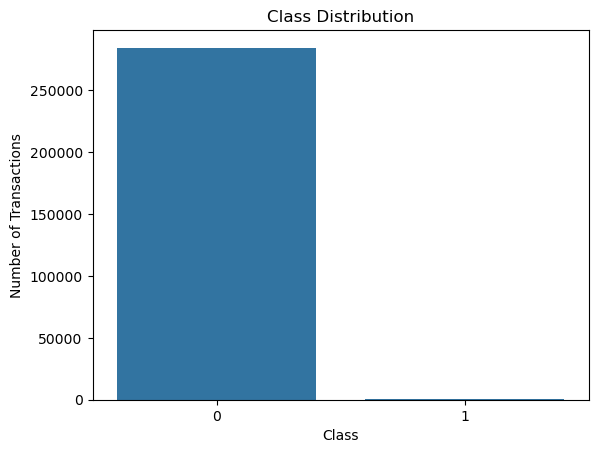


X Shape: (284807, 30)
y Shape: (284807,)

Training Data Shape: (199364, 30)
Testing Data Shape: (85443, 30)

Training Class Distribution Before Oversampling:
Counter({0: 199020, 1: 344})

Testing Class Distribution:
Counter({0: 85295, 1: 148})

Training Class Distribution After Oversampling:
Counter({0: 199020, 1: 199020})

Resampled Training Data Shape:
(398040, 30)

Training Random Forest...
Training Completed!

Number of Errors: 43

Confusion Matrix:
[[85291     4]
 [   39   109]]


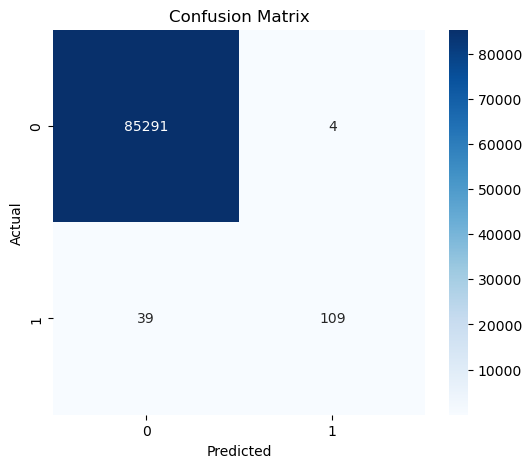


Accuracy: 0.9994967405170698
Accuracy (%): 99.94967405170698

Precision: 0.9646017699115044
Precision (%): 96.46017699115043

Recall: 0.7364864864864865
Recall (%): 73.64864864864865

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.96      0.74      0.84       148

    accuracy                           1.00     85443
   macro avg       0.98      0.87      0.92     85443
weighted avg       1.00      1.00      1.00     85443



In [1]:

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

from imblearn.over_sampling import RandomOverSampler

dataset = pd.read_csv("C:/Users/ushma/Downloads/creditcard.csv")

print("Dataset Shape:", dataset.shape)

print("\nMissing Values:")
print(dataset.isna().sum())


print("\nOriginal Class Distribution:")
print(Counter(dataset["Class"]))

sns.countplot(x=dataset["Class"])
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.show()

X = dataset.iloc[:, :-1]
y = dataset.iloc[:, -1]

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution Before Oversampling:")
print(Counter(y_train))

print("\nTesting Class Distribution:")
print(Counter(y_test))


ros = RandomOverSampler(random_state=0)

X_train_res, y_train_res = ros.fit_resample(
    X_train,
    y_train
)

print("\nTraining Class Distribution After Oversampling:")
print(Counter(y_train_res))

print("\nResampled Training Data Shape:")
print(X_train_res.shape)


classifier = RandomForestClassifier(
    n_estimators=641,
    random_state=0,
    n_jobs=-1
)


print("\nTraining Random Forest...")

classifier.fit(
    X_train_res,
    y_train_res
)

print("Training Completed!")

y_pred = classifier.predict(X_test)



n_errors = (y_pred != y_test).sum()

print("\nNumber of Errors:", n_errors)

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)


precision = precision_score(y_test, y_pred)

print("\nPrecision:", precision)
print("Precision (%):", precision * 100)

recall = recall_score(y_test, y_pred)

print("\nRecall:", recall)
print("Recall (%):", recall * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))